**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**05 | Python-First MATLAB Object Decoding and Signal Feasibility**

![Original Essex Python decoder and time-column schema audit](../../images/05_workflow.svg)

**Research question:** Can the original Essex MATLAB v5 object-backed IMU and model-derived e1e3 fields be decoded into finite, original-column-labelled numerical tables using Python instead of MATLAB Online/Desktop?

**Dataset:** Hollinger et al. (2026), *Scientific Data*, DOI [10.1038/s41597-026-07429-3](https://doi.org/10.1038/s41597-026-07429-3); original [Figshare 30225739 v13](https://doi.org/10.6084/m9.figshare.30225739.v13). Source registry: 40 participants, 1,897 original records, six activities. Notebooks 01–04 remain unchanged.

**Scientific motivation:** SciPy recovered source registry metadata but not validated numerical IMU/FE waveforms. The third-party mat-io package supports MATLAB MCOS objects and conversion of tables/timetables into pandas. Its executed pilot **did decode 28 labelled numeric IMU DataFrames of shape 101 × 43 and 27 FE DataFrames of shape 11 × 3**. The FE tables contain a non-numeric column; one additional FE source object is empty. Original column meanings and time-axis correspondence remain unverified. The 444-record BoneNet derivative is not substituted.

**Experimental sequence:** Pinned Python reader installation; official source checksum; selected files subj04, subj06, subj09 and subj44, including empty FE records; original participant/activity/trial identity reconciliation; genuine source-labelled finite numeric candidates; strict automatic full-source expansion only if the pilot passes.

**Quality boundary:** An opaque object pointer, uint32 metadata or unlabelled ndarray is not a verified signal. Neither time-axis dimensions nor successful conversion establish physical units, FE strain semantics, time alignment or model readiness. No model training, interpolation or invented IMU/FE values occur.

**Evidence:** CSV/JSON/PNG diagnostics are recorded in output files prefixed 05_. Private original MAT files and any recovered full-source numeric export are kept outside GitHub. The workflow SVG above summarises the verified pilot and blocked full-export gate. A further source-column/index audit has been added; its results still require execution. The diagram makes no claim of model readiness.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}


# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")
import json
import sys
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import whosmat
from IPython.display import display

from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab
from essex_figshare import (
    ARTICLE_ID, ARTICLE_VERSION, fetch_version_manifest,
    find_published_file, ensure_source_file, inspect_matlab_archive,
    extract_matlab_files,
)
from essex_numeric_recovery import check_record_registry
from essex_python_first import (
    PILOT_SUBJECTS, select_representative_rows, probe_pilot,
    evaluate_pilot, pilot_allows_expansion, export_full_source, sha256_file,
)

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4))
study_dir = root / "biomechanical_load_estimation"
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
output_dir = study_dir / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Original Figshare version:", ARTICLE_ID, ARTICLE_VERSION)
print("Python:", sys.version.split()[0])
print("Research outputs:", output_dir)

Original Figshare version: 30225739 13
Python: 3.13.18
Research outputs: /content/human-movement-intelligence/biomechanical_load_estimation/output


**02. Reproducible `mat-io` Installation in Colab**

This scientific dependency belongs in its **own installation cell**, not the Imports or approved Colab Setup. The first pilot successfully used `mat-io==1.0.1`. Its installation, however, upgraded NumPy to 2.5.4, conflicting with the preinstalled `numba 0.61.2` requirement of NumPy below 2.3. This warning did not invalidate the already completed pilot, but should be avoided in new runs.

The corrected installation verifies the required scientific libraries and installs **only the pinned binary reader wheel** with `--no-deps`. It will not change NumPy, pandas or SciPy during a running kernel. If minimum requirements are absent, it stops with a clear message rather than silently altering active scientific packages.

Use a fresh Colab Python 3.11–3.13 runtime; no MATLAB or local Windows installation is needed. [mat-io 1.0.1](https://pypi.org/project/mat-io/1.0.1/) · [Numba compatibility](https://numba.readthedocs.io/en/stable/user/installing.html).

In [ ]:
# ========== 02. Install and Verify the Pinned MATLAB Object Reader ===========

if not (3, 11) <= sys.version_info[:2] <= (3, 13):
    raise RuntimeError(
        "This pinned mat-io wheel workflow requires Colab Python 3.11–3.13. "
        "Python 3.14 may require building C extensions; do not install "
        "Microsoft C++ build tools for this Colab experiment."
    )

# Leave Colab's already-imported NumPy/SciPy/pandas unchanged.
# Verify dependencies before installing this reader without dependencies.
from packaging.version import Version
requirements = {
    "numpy": "2.2.2", "scipy": "1.15.0",
    "pandas": "2.2.0", "h5py": "3.13.0",
}
for dep, min_version in requirements.items():
    if Version(version(dep)) < Version(min_version):
        raise RuntimeError(
            f"{dep} must be at least {min_version}; choose a compatible "
            "fresh Colab runtime rather than upgrading imported packages."
        )

%pip -q install --only-binary=:all: --no-deps "mat-io==1.0.1"

from matio import load_from_mat
assert version("mat-io") == "1.0.1"
print("mat-io version:", version("mat-io"))
print("MATLAB table conversion API: AVAILABLE")

**03. Restore the Original Figshare Source**

This notebook downloads the original approximately 225 MiB MATLAB.zip from official Figshare v13 into private raw-data storage and verifies its checksum against Stage 02/03 approved evidence. ZIP integrity and all 40 original source MAT filenames are verified before any decoder runs. The original raw source files are not added to GitHub.

In [4]:
# ============ 03. Official Dataset Version and Archive Integrity =============

source_gate = json.loads(
    (output_dir / "02_record_provenance_and_quality_gate.json")
    .read_text(encoding="utf-8")
)
prior_gate = json.loads(
    (output_dir / "03_numeric_recovery_quality_gate.json")
    .read_text(encoding="utf-8")
)
assert source_gate["source_article_id"] == ARTICLE_ID
assert source_gate["version"] == ARTICLE_VERSION
assert source_gate["source_registry_gate"] == "PASSED"
assert source_gate["archive_sha256"] == prior_gate["archive_sha256"]

article, published_files = fetch_version_manifest()
archive_info = find_published_file(published_files, "MATLAB.zip")
zip_path, source_hash = ensure_source_file(archive_info, raw_dir)
if source_hash["sha256"] != source_gate["archive_sha256"]:
    raise ValueError("Original Essex MATLAB source SHA256 mismatch.")
zip_inventory = inspect_matlab_archive(zip_path, expected_mat_files=40)
mat_files = extract_matlab_files(zip_path, mat_dir, zip_inventory)
assert len(mat_files) == 40
print("Original source integrity: PASSED")
print("Participant MAT files:", len(mat_files))
print("Original source SHA256:", source_hash["sha256"])

Original source integrity: PASSED
Participant MAT files: 40
Original source SHA256: c50f10d1364686412b7ab64cac435dc85864dc8dbb34d2804b9cf37f2e29132d


**04. Frozen Source-Record Registry and Pilot Selection**

The prior original registry contains exact zero-based Data record indexes, participant IDs, original source filenames, activities, UpdatedTrialID, and FE source representation status. Every candidate numerical record is checked against those original fields. Four files are inspected, preserving cross-activity and FE-empty evidence where available.

In [5]:
# ========= 04. Original Participant and Source-Record Pilot Identity =========

registry = pd.read_csv(
    output_dir / "02_original_record_registry.csv",
    dtype={
        "subject_id": "string", "source_file": "string",
        "local_record_key": "string", "task": "string",
        "updated_trial_id": "string", "fe_representation": "string",
    }
)
registry_summary = check_record_registry(registry, source_gate)
assert registry_summary["records"] == 1897
assert registry_summary["participants"] == 40
assert {x.stem.lower() for x in mat_files} == set(registry["subject_id"])
assert int(registry["fe_representation"].eq("empty").sum()) == 168

selected = select_representative_rows(
    registry, subjects=PILOT_SUBJECTS, max_each=8
)
selected.to_csv(
    output_dir / "05_python_first_pilot_selection.csv", index=False
)
display(selected[[
    "subject_id", "task", "updated_trial_id",
    "local_record_key", "fe_representation",
]])
print("Original pilot records:", len(selected))

,subject_id,task,updated_trial_id,local_record_key,fe_representation
0,subj04,CounterJumps,CounterJumpsMax1,subj04:0000,structured_or_opaque
1,subj04,Running,RunningFast1,subj04:0009,structured_or_opaque
2,subj04,SquatJumps,SquatJumpsMax1,subj04:0018,structured_or_opaque
3,subj04,Walking,Walking1,subj04:0027,structured_or_opaque
4,subj04,BilateralHopping,BilateralHoppingMin1,subj04:0030,structured_or_opaque
5,subj04,UnilateralHopping,UnilateralHoppingMin1,subj04:0039,structured_or_opaque
6,subj04,UnilateralHopping,UnilateralHoppingMax3,subj04:0047,structured_or_opaque
7,subj06,CounterJumps,CounterJumpsMax1,subj06:0000,structured_or_opaque
8,subj06,Running,RunningFast1,subj06:0009,structured_or_opaque
9,subj06,SquatJumps,SquatJumpsMax1,subj06:0018,structured_or_opaque


Original pilot records: 28


**05. Original MAT Container Preflight**

The SciPy header inspection reports source MAT variables without pretending to decode their object values. In particular, any __function_workspace__ variable is internal MATLAB storage and not an IMU waveform. Only variable names, MATLAB classes and dimensions are exported.

In [6]:
# ============== 05. Original MATLAB File and Container Metadata ==============

preflight_rows = []
for subject in PILOT_SUBJECTS:
    path = mat_dir / f"{subject}.mat"
    for variable, shape, matlab_class in whosmat(path):
        preflight_rows.append({
            "subject_id": subject, "source_file": path.name,
            "variable": variable, "shape": str(tuple(shape)),
            "matlab_class": matlab_class,
        })
preflight = pd.DataFrame(preflight_rows)
for subject in PILOT_SUBJECTS:
    assert "Data" in set(
        preflight.loc[preflight["subject_id"] == subject, "variable"]
    )
preflight.to_csv(
    output_dir / "05_python_first_source_preflight.csv", index=False
)
display(preflight)

,subject_id,source_file,variable,shape,matlab_class
0,subj04,subj04.mat,Data,"(48, 1)",struct
1,subj04,subj04.mat,__function_workspace__,"(1, 7787968)",uint8
2,subj06,subj06.mat,Data,"(48, 1)",struct
3,subj06,subj06.mat,__function_workspace__,"(1, 7759456)",uint8
4,subj09,subj09.mat,Data,"(42, 1)",struct
5,subj09,subj09.mat,__function_workspace__,"(1, 6814624)",uint8
6,subj44,subj44.mat,Data,"(48, 1)",struct
7,subj44,subj44.mat,__function_workspace__,"(1, 7787968)",uint8


**06. Independent Python-First MCOS Object Decoding**

matio.load_from_mat reads the original Data variable in decoded mode. An original-field value is eligible as a finite numeric candidate only when it is a pandas DataFrame with genuine distinct column labels, real numerical values and fully matched source participant, Task and UpdatedTrialID. Read failures and unresolved classes are recorded as findings.

Original FE-empty records are not assigned synthetic targets. The reader is probed on four complete original source files, but only selected source records are inspected for candidate signals.

**Observed pilot result:** The reader matched all 28 original trial identities without file-level errors. IMU tables are 101 × 43, while 27 FE tables are 11 × 3 and include a non-numeric column. No time/index column may be removed merely to force the expected tensor dimensions. The source-column/index audit below investigates the original names and dtypes before numerical export.

In [7]:
# ================ 06. Source-Linked IMU and FE Decoder Pilot =================

pilot, errors, decoded = probe_pilot(
    load_from_mat, mat_dir, selected
)
assert len(pilot) == 2 * len(selected)
pilot.to_csv(
    output_dir / "05_python_first_decode_audit.csv", index=False
)
errors.to_csv(
    output_dir / "05_python_first_reader_errors.csv", index=False
)
print("Original record-modality probes:", len(pilot))
print("File-level decoding errors:", len(errors))
print("Original-column-labelled numeric candidates:", len(decoded))
display(pilot[[
    "source_file", "local_record_index", "modality",
    "decode_status", "source_identity_match",
    "python_class", "shape", "n_time", "n_channels",
]].head(30))
if not errors.empty:
    display(errors)

Original record-modality probes: 56
File-level decoding errors: 0
Original-column-labelled numeric candidates: 28


,source_file,local_record_index,modality,decode_status,source_identity_match,python_class,shape,n_time,n_channels
0,subj04.mat,0,IMU,labelled_numeric_table,True,DataFrame,"(101, 43)",101,43
1,subj04.mat,0,FE,non_numeric_table,True,DataFrame,"(11, 3)",0,0
2,subj04.mat,9,IMU,labelled_numeric_table,True,DataFrame,"(101, 43)",101,43
3,subj04.mat,9,FE,non_numeric_table,True,DataFrame,"(11, 3)",0,0
4,subj04.mat,18,IMU,labelled_numeric_table,True,DataFrame,"(101, 43)",101,43
5,subj04.mat,18,FE,non_numeric_table,True,DataFrame,"(11, 3)",0,0
6,subj04.mat,27,IMU,labelled_numeric_table,True,DataFrame,"(101, 43)",101,43
7,subj04.mat,27,FE,non_numeric_table,True,DataFrame,"(11, 3)",0,0
8,subj04.mat,30,IMU,labelled_numeric_table,True,DataFrame,"(101, 43)",101,43
9,subj04.mat,30,FE,non_numeric_table,True,DataFrame,"(11, 3)",0,0


**06A. Original MATLAB Column Types and Time-Index Schema**

The first Python-first pilot returned 101 × 43 IMU DataFrames and 11 × 3 FE DataFrames, rather than the prespecified 101 × 42 and 11 × 2 arrays. The extra columns could be time/index information or another source field; **their roles have not been verified**.

This focused audit records every original column label, numeric or nonnumeric dtype, first non-null value class, null count and pandas index metadata. No raw sample values are exported, no column is dropped, and any candidate time label remains scientifically unverified until the original source documentation supports it.

Two reproducible metadata files are generated: `05_python_first_column_schema.csv` and `05_python_first_index_schema.csv`.

In [ ]:
# ============= 06A. Original Column and Time-Index Schema Audit ==============

from essex_python_first import inspect_native_table_schema

column_schema, index_schema = inspect_native_table_schema(
    load_from_mat, mat_dir, selected
)
column_schema.to_csv(
    output_dir / "05_python_first_column_schema.csv", index=False
)
index_schema.to_csv(
    output_dir / "05_python_first_index_schema.csv", index=False
)
column_summary = (
    column_schema.groupby(
        ["modality", "original_column_name", "pandas_dtype",
         "is_numeric_dtype", "is_time_label_candidate"],
        dropna=False,
    ).size().rename("source_records").reset_index()
)
print("Original table-column metadata rows:", len(column_schema))
print("Source-index metadata records:", len(index_schema))
display(column_summary.head(100))
display(index_schema.groupby(
    ["modality", "table_class", "n_rows", "n_columns", "index_class"],
    dropna=False,
).size().rename("source_records").reset_index())
print("No original column excluded or relabelled.")

**07. Reader Results, Candidate Semantics and Expansion Gate**

Source identity, finite numeric tables, channel labels and original-array shapes are assessed separately. Automatic full-source conversion is permitted only when every pilot record identity matches, every pilot IMU has an original-labelled 101-by-42 matrix, every nonempty FE record has two original e1/e3 columns and 11 candidate source positions, and expected empty FE fields remain empty.

These are strict **candidate** conditions, not physical-unit or temporal-alignment verification. They do not allow regression training.

In [8]:
# ======== 07. Source-Labelled Numeric Candidate and Full Export Gate =========

pilot_results = evaluate_pilot(pilot, errors)
allow_full = pilot_allows_expansion(pilot, errors)

status = (
    pilot.groupby(["modality", "decode_status"])
    .size().rename("count").reset_index()
)
status.to_csv(
    output_dir / "05_python_first_decoding_status.csv", index=False
)
candidates = pilot.loc[
    pilot["decode_status"] == "labelled_numeric_table"
].copy()
candidates.to_csv(
    output_dir / "05_python_first_labelled_candidates.csv", index=False
)
display(status)
print("Reader-error files:", pilot_results["reader_error_files"])
print("Verified original record identities:",
      pilot_results["identity_matches"])
print("Finite named IMU tables:", pilot_results["labelled_numeric_imu"])
print("Finite named FE tables:", pilot_results["labelled_numeric_fe"])
print("Candidate 101 x 42 IMU tables:",
      pilot_results["imu_101_42_pairs"])
print("Candidate FE 11-point e1/e3 tables:",
      pilot_results["fe_11_e1e3_pairs"])
print("Full-source expansion:", "PASSED" if allow_full else "BLOCKED")

,modality,decode_status,count
0,FE,non_numeric_table,27
1,FE,unsupported_class,1
2,IMU,labelled_numeric_table,28


Reader-error files: 0
Verified original record identities: 28
Finite named IMU tables: 28
Finite named FE tables: 0
Candidate 101 x 42 IMU tables: 0
Candidate FE 11-point e1/e3 tables: 0
Full-source expansion: BLOCKED


**08. Research Diagnostic Figure**

The left panel shows actual Python decoder outcomes for IMU and FE fields. The right panel shows an authentic first-column source IMU trace only when a finite, original-column-labelled DataFrame was recovered. Otherwise it reports that a genuine numerical waveform remains unavailable. No simulated curves or FE strain reconstructions are plotted.

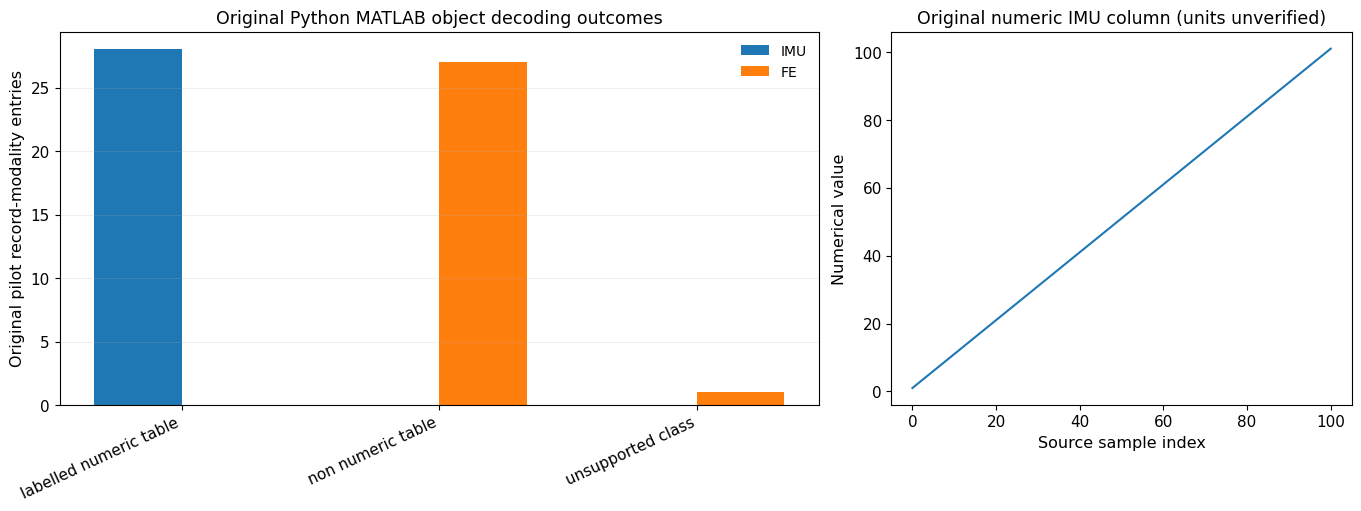

In [9]:
# ========= 08. Source-Object Reader Diagnostics and Real-Signal Plot =========

fig, ax = plt.subplots(
    1, 2, figsize=(13.5, 5),
    gridspec_kw={"width_ratios": [1.65, 1.0]},
    constrained_layout=True,
)
by_status = status.pivot(
    index="decode_status", columns="modality", values="count"
).fillna(0).astype(int).sort_index()
x = np.arange(len(by_status))
w = 0.34
for off, label in [(-0.5, "IMU"), (0.5, "FE")]:
    values = (
        by_status[label].to_numpy()
        if label in by_status else np.zeros(len(by_status))
    )
    ax[0].bar(x + off * w, values, w, label=label)
ax[0].set_xticks(x)
ax[0].set_xticklabels(
    [v.replace("_", " ") for v in by_status.index],
    rotation=25, ha="right"
)
ax[0].set_title("Original Python MATLAB object decoding outcomes")
ax[0].set_ylabel("Original pilot record-modality entries")
ax[0].legend(frameon=False)
ax[0].grid(axis="y", alpha=0.2)

imu_keys = [k for k in decoded if k[1] == "IMU"]
if imu_keys:
    real_values, original_names = decoded[imu_keys[0]]
    ax[1].plot(
        np.arange(real_values.shape[0]),
        real_values[:, 0], linewidth=1.5
    )
    ax[1].set_title("Original numeric IMU column (units unverified)")
    ax[1].set_xlabel("Source sample index")
    ax[1].set_ylabel("Numerical value")
else:
    ax[1].text(
        0.5, 0.5, "No source-labelled numerical IMU waveform",
        ha="center", va="center", transform=ax[1].transAxes
    )
    ax[1].set_title("Authentic numerical waveform availability")
    ax[1].set_xticks([])
    ax[1].set_yticks([])
save_figure(fig, output_dir / "05_python_first_decoder_diagnostics.png")
plt.show()

**09. Fully Gated All-Participant Python Export**

Only if the **entire pilot** passes its strict checks does this cell attempt conversion of all 40 source MAT files. Every source identity, original column name and expected FE-empty representation must be preserved. Any unexpected conversion stops and is recorded. A successful output is private and produces native_essex_export.zip for subsequent verification by Notebook 04.

**Important provenance:** The exported manifest uses Notebook 04's numeric file format, but its README explicitly declares Python mat-io conversion, NOT MATLAB-native export. Even a full numeric export does not establish biomedical units or temporal alignment.

In [10]:
# ======== 09. Guarded Python Conversion of All Original Essex Records ========

export_state = "BLOCKED_BY_PILOT"
export_error = None
export_zip = None
export_manifest = None
if allow_full:
    try:
        export_manifest, export_zip = export_full_source(
            load_from_mat, mat_dir, registry,
            raw_dir / "python_matio_full_export",
            Path("/content/native_essex_export.zip"),
        )
        export_state = "PYTHON_NUMERIC_EXPORT_CREATED"
    except Exception as exc:
        export_state = "FULL_EXPORT_FAILED_VALIDATION"
        export_error = f"{type(exc).__name__}: {str(exc)[:350]}"
print("Full original-source conversion:", export_state)
if export_error:
    print("Validation failure:", export_error)
if export_zip is not None:
    print("Private export ZIP:", export_zip)

if export_manifest is None:
    export_status = pd.DataFrame(columns=["modality", "status", "count"])
else:
    export_status = (
        export_manifest.groupby(["modality", "status"])
        .size().rename("count").reset_index()
    )
export_status.to_csv(
    output_dir / "05_python_first_full_export_status.csv", index=False
)
display(export_status)

Full original-source conversion: BLOCKED_BY_PILOT


,modality,status,count


**10. Scientific Quality Gate, Evidence Export and Review**
,
,This notebook records separate gates for reader compatibility, source record identities, finite original-labelled numeric objects and full-source conversion. Model readiness is always false until physical sensor units, FE principal-strain definitions, native FE time indices and input–target temporal alignment have been independently verified.
,
,**Manual action after execution:** Commit the executed Notebook 05 and all **eleven** 05_ summary files (CSV, JSON and PNG). Do not commit original MATLAB archives, decoded numeric arrays or the private numeric ZIP. After reviewing the output, the scientific workflow SVG will be created and inserted without a stage number in its visible heading.

In [ ]:
# ======= 10. Source-Backed Scientific Decision and Research Packaging ========

quality = {
    "source_article": ARTICLE_ID,
    "source_version": ARTICLE_VERSION,
    "source_sha256": source_hash["sha256"],
    "reader_package": "mat-io",
    "reader_version": version("mat-io"),
    "python_version": sys.version.split()[0],
    "pilot_subjects": list(PILOT_SUBJECTS),
    "source_records": int(len(registry)),
    "source_participants": int(registry["subject_id"].nunique()),
    "pilot_summary": pilot_results,
    "strict_expansion_gate": bool(allow_full),
    "full_source_export_state": export_state,
    "full_source_export_error": export_error,
    "full_export_sha256": sha256_file(export_zip) if export_zip else None,
    "source_integrity": "PASSED",
    "physical_units_verified": False,
    "fe_target_semantics_verified": False,
    "imu_fe_temporal_alignment_verified": False,
    "model_ready": False,
    "model_training_performed": False,
}
(output_dir / "05_python_first_quality_gate.json").write_text(
    json.dumps(quality, indent=2) + "\n", encoding="utf-8"
)
display(pd.DataFrame([{
    "pilot_records": pilot_results["sampled_original_records"],
    "reader_errors": pilot_results["reader_error_files"],
    "numeric_imu_tables": pilot_results["labelled_numeric_imu"],
    "numeric_fe_tables": pilot_results["labelled_numeric_fe"],
    "full_export_state": export_state,
    "regression_ready": False,
}]))
expected = [
    "05_python_first_pilot_selection.csv",
    "05_python_first_source_preflight.csv",
    "05_python_first_decode_audit.csv",
    "05_python_first_reader_errors.csv",
    "05_python_first_decoding_status.csv",
    "05_python_first_labelled_candidates.csv",
    "05_python_first_column_schema.csv",
    "05_python_first_index_schema.csv",
    "05_python_first_decoder_diagnostics.png",
    "05_python_first_full_export_status.csv",
    "05_python_first_quality_gate.json",
]
missing = [v for v in expected if not (output_dir / v).is_file()]
if missing:
    raise FileNotFoundError("Missing Python-first evidence: " + ", ".join(missing))
print("Scientific evidence files:", len(expected))
download_outputs_from_colab(
    folder="biomechanical_load_estimation/output", stage="05"
)